# Instituto / Universidad: **[NOMBRE DE LA INSTITUCIÓN]**

## Programa Educativo: Ingeniería en Computación

### Asignatura: Investigación de Operaciones

---

# Práctica 3. Algoritmo de Dijkstra (Ruta más corta)

**Actividad integradora:** Implementación de Modelos de Investigación de Operaciones mediante Python y Jupyter Notebook

**Periodo:** 2026-B

**Integrantes del equipo:**

| No. | Nombre completo | Matrícula |
|:---:|:----------------|:----------|
| 1 | [Nombre del integrante 1] | [Matrícula] |
| 2 | [Nombre del integrante 2] | [Matrícula] |
| 3 | [Nombre del integrante 3] | [Matrícula] |

**Fecha de elaboración:** 18 de noviembre de 2026

**Herramientas:** Python 3, Jupyter Notebook, NetworkX, Matplotlib, NumPy, Pandas y SciPy.

# 1. Título del problema

**Enrutamiento de paquetes de menor latencia entre un servidor y un cliente a través de una red de routers**

# 2. Descripción y planteamiento

Un servidor de aplicaciones (**S**) debe enviar datos a un cliente remoto (**D**) atravesando una red de **7 routers intermedios** (R1 a R7). Entre algunos pares de dispositivos existe un enlace cuya **latencia** (retardo de propagación y cola) se mide en **milisegundos (ms)**. La red tiene **9 nodos y 16 enlaces**.

El objetivo es determinar la **ruta de menor latencia total** de S a D, es decir, la **ruta más corta** de la red, donde el "largo" de cada arco es el tiempo en milisegundos. Es una de las tres categorías de aplicación vistas en clase: *minimizar el tiempo total de una secuencia de actividades*.

**Relación con las Tecnologías de la Información:** este es exactamente el problema que resuelven los protocolos de enrutamiento de **estado de enlace** como **OSPF** e **IS-IS** (cada router ejecuta Dijkstra sobre el mapa de la red), así como los sistemas de balanceo de carga, CDN y redes definidas por software (SDN).

# 3. Formulación matemática

Sea la red $R=(N,A)$ con $N$ el conjunto de nodos, $A$ el conjunto de arcos y $c_{ij}\ge 0$ la latencia del enlace $(i,j)$. Como los enlaces son bidireccionales, cada enlace genera dos arcos dirigidos $(i,j)$ y $(j,i)$ con el mismo costo.

**Formulación como programa lineal** (flujo de una unidad desde el origen hasta el destino):

$$x_{ij}=\begin{cases}1 & \text{si el arco }(i,j)\text{ forma parte de la ruta}\\0 & \text{en otro caso}\end{cases}$$

$$\min Z=\sum_{(i,j)\in A} c_{ij}\,x_{ij}$$

$$\sum_{j:(i,j)\in A}x_{ij}-\sum_{k:(k,i)\in A}x_{ki}=\begin{cases}1 & i=S\\-1 & i=D\\0 & \text{otro nodo}\end{cases}\qquad x_{ij}\ge 0$$

**Algoritmo de Dijkstra.** A cada nodo $v$ se le asigna una etiqueta $d(v)$ = mejor distancia conocida desde $S$ y un predecesor $\pi(v)$:

1. **Inicio:** $d(S)=0$ y $d(v)=\infty$ para los demás. Todas las etiquetas son *temporales*.
2. **Selección:** se toma el nodo $u$ con etiqueta temporal **mínima** y se vuelve **permanente** (ya no cambia).
3. **Relajación:** para cada vecino $v$ aún temporal: si $d(u)+c_{uv}<d(v)$ entonces $d(v)\leftarrow d(u)+c_{uv}$ y $\pi(v)\leftarrow u$.
4. Repetir 2 y 3 hasta que el destino $D$ sea permanente. La ruta se reconstruye siguiendo los predecesores desde $D$ hasta $S$.

El algoritmo es correcto cuando **todos los $c_{ij}\ge 0$**, condición que cumplen las latencias.

# 4. Importación de bibliotecas

Además de las bibliotecas habituales se importa `linprog` de **SciPy** para validar la ruta resolviendo el modelo de programación lineal, e `islice` para listar rutas alternativas.

In [1]:
import itertools
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.optimize import linprog

print("NumPy    :", np.__version__)
print("Pandas   :", pd.__version__)
print("NetworkX :", nx.__version__)
print("Bibliotecas importadas correctamente.")

NumPy    : 2.1.3
Pandas   : 2.2.3
NetworkX : 3.4.2
Bibliotecas importadas correctamente.


# 5. Definición de datos

Se define la red de **9 nodos** (servidor **S**, routers **R1–R7** y cliente **D**) y los **16 enlaces** con su latencia en ms. Los datos se guardan en el archivo complementario `p3_enlaces_red.csv`. La red es **no dirigida** (los enlaces funcionan en ambos sentidos).

In [2]:
nodos = ["S", "R1", "R2", "R3", "R4", "R5", "R6", "R7", "D"]

# (nodo_a, nodo_b, latencia en ms)
enlaces = [
    ("S", "R1", 4),  ("S", "R2", 7),  ("R1", "R2", 2), ("R1", "R3", 10),
    ("R2", "R4", 6), ("R2", "R5", 11), ("R3", "R4", 3), ("R3", "R6", 8),
    ("R3", "R7", 5), ("R4", "R5", 4), ("R4", "R6", 9), ("R5", "R6", 2),
    ("R5", "D", 5),  ("R6", "R7", 3), ("R6", "D", 6),  ("R7", "D", 3),
]

df_enl = pd.DataFrame(enlaces, columns=["nodo_a", "nodo_b", "latencia_ms"])
df_enl.to_csv("p3_enlaces_red.csv", index=False)
print("Nodos  :", len(nodos))
print("Enlaces:", len(enlaces))
print()
print(df_enl.to_string(index=False))

G = nx.Graph()
G.add_nodes_from(nodos)
G.add_weighted_edges_from(enlaces)

print("\n¿La red es conexa? ->", nx.is_connected(G))
print("¿Todas las latencias son >= 0 (requisito de Dijkstra)? ->", all(w >= 0 for _, _, w in enlaces))

origen, destino = "S", "D"
print(f"\nOrigen: {origen}   Destino: {destino}")

pos = {"S": (0, 2), "R1": (1.7, 3.6), "R2": (1.7, 0.6), "R3": (4.0, 3.8), "R4": (3.8, 1.8),
       "R5": (5.2, 0.4), "R6": (5.6, 2.2), "R7": (6.6, 3.7), "D": (8.0, 2.0)}

Nodos  : 9
Enlaces: 16

nodo_a nodo_b  latencia_ms
     S     R1            4
     S     R2            7
    R1     R2            2
    R1     R3           10
    R2     R4            6
    R2     R5           11
    R3     R4            3
    R3     R6            8
    R3     R7            5
    R4     R5            4
    R4     R6            9
    R5     R6            2
    R5      D            5
    R6     R7            3
    R6      D            6
    R7      D            3

¿La red es conexa? -> True
¿Todas las latencias son >= 0 (requisito de Dijkstra)? -> True

Origen: S   Destino: D


## 5.1 Función de graficación

La función `dibujar` muestra, en cada iteración, la etiqueta de distancia de cada nodo (debajo de su nombre). Código de colores: **verde** = etiqueta permanente, **naranja** = nodo que se acaba de volver permanente, **azul claro** = etiqueta temporal finita, **gris** = distancia aún infinita ($\infty$). Las aristas **verdes gruesas** son los predecesores de nodos permanentes, las **azules punteadas** los predecesores provisionales y las **naranjas** los enlaces que mejoraron una etiqueta en la iteración actual.

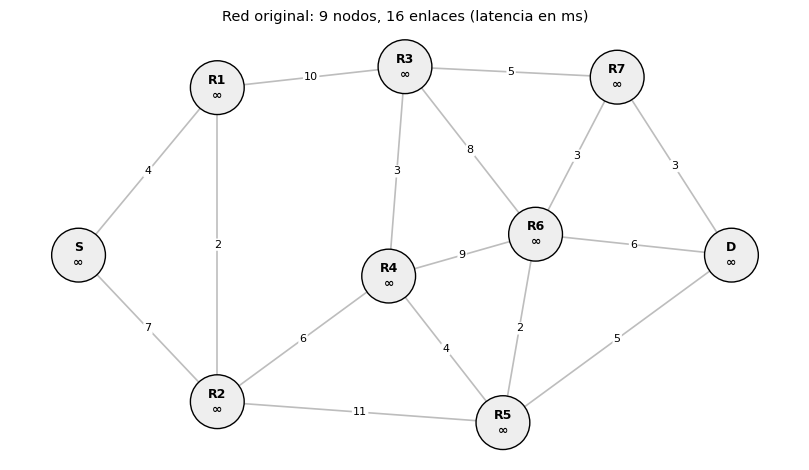

In [3]:
def dibujar(G, pos, dist, pred, permanentes, actual=None, mejoradas=(), camino=None, titulo="", ax=None):
    propio = ax is None
    if propio:
        fig, ax = plt.subplots(figsize=(8.2, 4.8))
    nx.draw_networkx_edges(G, pos, edge_color="#bdbdbd", width=1.2, ax=ax)

    perm_edges = [(pred[v], v) for v in permanentes if pred[v] is not None]
    temp_edges = [(pred[v], v) for v in G if v not in permanentes and pred[v] is not None]
    nx.draw_networkx_edges(G, pos, edgelist=temp_edges, edge_color="#1e88e5", width=2.5, style="dashed", ax=ax)
    nx.draw_networkx_edges(G, pos, edgelist=perm_edges, edge_color="#2e7d32", width=4, ax=ax)
    nx.draw_networkx_edges(G, pos, edgelist=list(mejoradas), edge_color="#fb8c00", width=3.5, style="dashed", ax=ax)
    if camino:
        nx.draw_networkx_edges(G, pos, edgelist=list(zip(camino[:-1], camino[1:])), edge_color="#d32f2f", width=6, ax=ax)

    colores = []
    for n in G.nodes():
        if camino and n in camino:
            colores.append("#ef9a9a")
        elif n == actual:
            colores.append("#ffb74d")
        elif n in permanentes:
            colores.append("#a5d6a7")
        elif np.isfinite(dist[n]):
            colores.append("#bbdefb")
        else:
            colores.append("#eeeeee")
    nx.draw_networkx_nodes(G, pos, node_color=colores, node_size=1500, edgecolors="black", ax=ax)
    etiquetas = {n: f"{n}\n" + ("∞" if not np.isfinite(dist[n]) else str(int(dist[n]))) for n in G.nodes()}
    nx.draw_networkx_labels(G, pos, labels=etiquetas, font_size=9, font_weight="bold", ax=ax)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"), font_size=8,
                                 rotate=False, ax=ax, bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none"))
    ax.set_title(titulo, fontsize=10.5)
    ax.axis("off")
    if propio:
        plt.tight_layout()
        plt.show()


# Red original
inf = float("inf")
dist0 = {n: inf for n in nodos}
pred0 = {n: None for n in nodos}
dibujar(G, pos, dist0, pred0, [], titulo="Red original: 9 nodos, 16 enlaces (latencia en ms)")

# 6. Desarrollo del algoritmo

## 6.1 Implementación de Dijkstra como generador (paso 0: inicialización)

Cada llamada a `next(pasos)` ejecuta **una iteración** completa: (1) elige el nodo temporal de menor distancia y lo hace permanente, y (2) **relaja** los enlaces hacia sus vecinos temporales. La función `mostrar_iteracion` imprime la tabla de relajaciones, la tabla de etiquetas y grafica el estado.

**Paso 0 – Inicialización:** $d(S)=0$, $d(v)=\infty$ para todos los demás y ningún nodo es permanente.

PASO 0: inicialización
nodo distancia predecesor etiqueta
   S         0          - temporal
  R1         ∞          - temporal
  R2         ∞          - temporal
  R3         ∞          - temporal
  R4         ∞          - temporal
  R5         ∞          - temporal
  R6         ∞          - temporal
  R7         ∞          - temporal
   D         ∞          - temporal


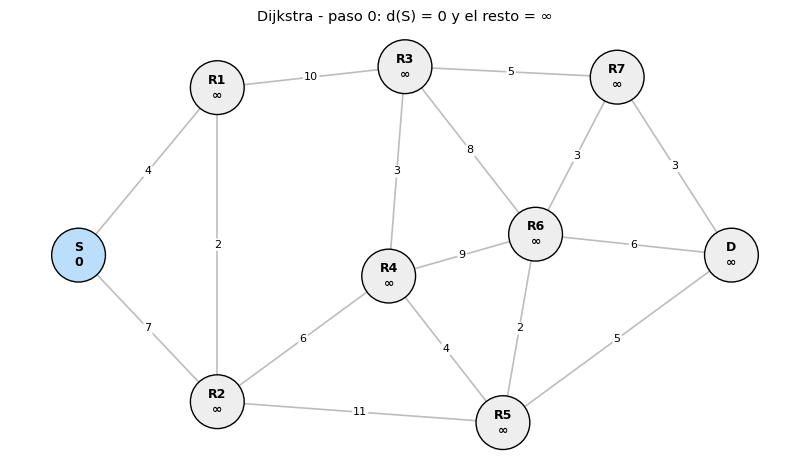

In [4]:
def dijkstra_pasos(G, origen):
    dist = {n: float("inf") for n in G}
    pred = {n: None for n in G}
    dist[origen] = 0
    permanentes = []
    while len(permanentes) < G.number_of_nodes():
        # 1) nodo temporal con menor distancia
        u = min((n for n in G if n not in permanentes), key=lambda n: dist[n])
        permanentes.append(u)
        # 2) relajacion de los enlaces hacia vecinos temporales
        relajaciones = []
        for v in G[u]:
            if v in permanentes:
                continue
            nueva = dist[u] + G[u][v]["weight"]
            mejora = nueva < dist[v]
            relajaciones.append((v, dist[v], G[u][v]["weight"], nueva, mejora))
            if mejora:
                dist[v] = nueva
                pred[v] = u
        yield {"u": u, "dist": dict(dist), "pred": dict(pred),
               "permanentes": list(permanentes), "relajaciones": relajaciones}


def mostrar_iteracion(k, e):
    u = e["u"]
    print(f"ITERACIÓN {k}: el nodo {u} se vuelve PERMANENTE con d({u}) = {int(e['dist'][u])} ms\n")
    if e["relajaciones"]:
        filas = []
        for v, ant, w, nueva, mejora in e["relajaciones"]:
            filas.append([v, "∞" if ant == float("inf") else int(ant),
                          f"d({u}) + {w} = {int(nueva)}", "SÍ -> se actualiza" if mejora else "no"])
        print("Relajación de los vecinos temporales:")
        print(pd.DataFrame(filas, columns=["vecino", "d actual", "d(u) + c(u,v)", "¿mejora?"]).to_string(index=False))
    else:
        print("No hay vecinos temporales por relajar.")

    estado = pd.DataFrame({
        "nodo": nodos,
        "distancia": ["∞" if e["dist"][n] == float("inf") else int(e["dist"][n]) for n in nodos],
        "predecesor": [e["pred"][n] if e["pred"][n] else "-" for n in nodos],
        "etiqueta": ["PERMANENTE" if n in e["permanentes"] else "temporal" for n in nodos],
    })
    print("\nEstado de las etiquetas:")
    print(estado.to_string(index=False))
    mejoradas = [(u, v) for v, ant, w, nueva, mejora in e["relajaciones"] if mejora]
    dibujar(G, pos, e["dist"], e["pred"], e["permanentes"], actual=u, mejoradas=mejoradas,
            titulo=f"Dijkstra - iteración {k}: nodo {u} permanente (d = {int(e['dist'][u])} ms)")


pasos = dijkstra_pasos(G, origen)
k_iter = 0

dist_ini = dict(dist0); dist_ini[origen] = 0
print("PASO 0: inicialización")
print(pd.DataFrame({"nodo": nodos, "distancia": [0 if n == origen else "∞" for n in nodos],
                    "predecesor": ["-"] * len(nodos), "etiqueta": ["temporal"] * len(nodos)}).to_string(index=False))
dibujar(G, pos, dist_ini, pred0, [], actual=None, titulo="Dijkstra - paso 0: d(S) = 0 y el resto = ∞")

# 7. Ejecución paso a paso

Cada celda ejecuta **una iteración** del algoritmo. En total son **9 iteraciones** (una por nodo); el destino D será el último en volverse permanente.

## Iteración 1 de 9

**S** tiene la etiqueta mínima (0) y se vuelve permanente. Se actualizan sus vecinos: $d(R1)=4$ y $d(R2)=7$.

ITERACIÓN 1: el nodo S se vuelve PERMANENTE con d(S) = 0 ms

Relajación de los vecinos temporales:
vecino d actual d(u) + c(u,v)           ¿mejora?
    R1        ∞  d(S) + 4 = 4 SÍ -> se actualiza
    R2        ∞  d(S) + 7 = 7 SÍ -> se actualiza

Estado de las etiquetas:
nodo distancia predecesor   etiqueta
   S         0          - PERMANENTE
  R1         4          S   temporal
  R2         7          S   temporal
  R3         ∞          -   temporal
  R4         ∞          -   temporal
  R5         ∞          -   temporal
  R6         ∞          -   temporal
  R7         ∞          -   temporal
   D         ∞          -   temporal


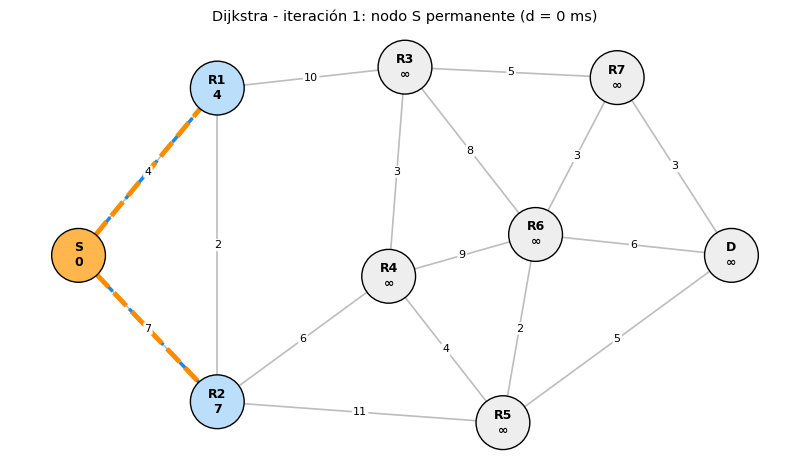

In [5]:
k_iter += 1
estado = next(pasos)
mostrar_iteracion(k_iter, estado)

## Iteración 2 de 9

**R1** (4) es el siguiente. Al relajar: $d(R2)$ **mejora** de 7 a 6 (pasando por R1: 4+2) y $d(R3)=14$.

ITERACIÓN 2: el nodo R1 se vuelve PERMANENTE con d(R1) = 4 ms

Relajación de los vecinos temporales:
vecino d actual   d(u) + c(u,v)           ¿mejora?
    R2        7   d(R1) + 2 = 6 SÍ -> se actualiza
    R3        ∞ d(R1) + 10 = 14 SÍ -> se actualiza

Estado de las etiquetas:
nodo distancia predecesor   etiqueta
   S         0          - PERMANENTE
  R1         4          S PERMANENTE
  R2         6         R1   temporal
  R3        14         R1   temporal
  R4         ∞          -   temporal
  R5         ∞          -   temporal
  R6         ∞          -   temporal
  R7         ∞          -   temporal
   D         ∞          -   temporal


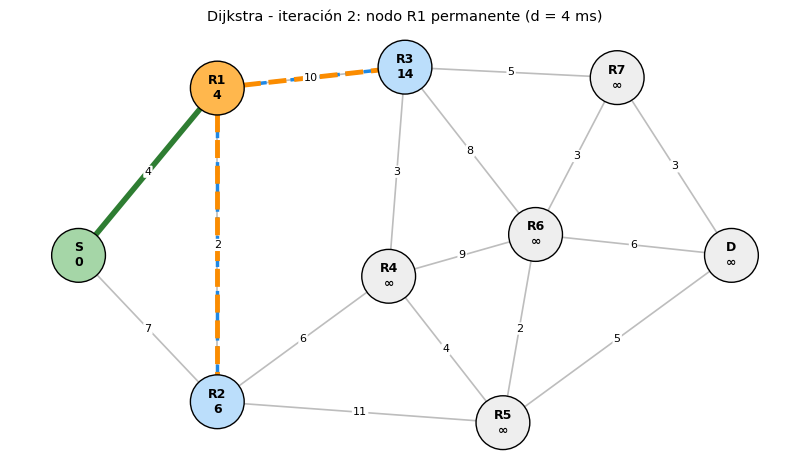

In [6]:
k_iter += 1
estado = next(pasos)
mostrar_iteracion(k_iter, estado)

## Iteración 3 de 9

**R2** (6) se vuelve permanente. Se fijan $d(R4)=12$ y $d(R5)=17$.

ITERACIÓN 3: el nodo R2 se vuelve PERMANENTE con d(R2) = 6 ms

Relajación de los vecinos temporales:
vecino d actual   d(u) + c(u,v)           ¿mejora?
    R4        ∞  d(R2) + 6 = 12 SÍ -> se actualiza
    R5        ∞ d(R2) + 11 = 17 SÍ -> se actualiza

Estado de las etiquetas:
nodo distancia predecesor   etiqueta
   S         0          - PERMANENTE
  R1         4          S PERMANENTE
  R2         6         R1 PERMANENTE
  R3        14         R1   temporal
  R4        12         R2   temporal
  R5        17         R2   temporal
  R6         ∞          -   temporal
  R7         ∞          -   temporal
   D         ∞          -   temporal


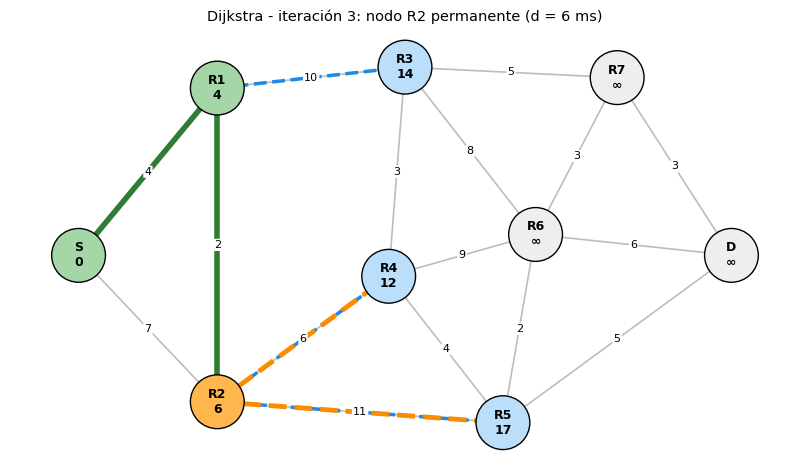

In [7]:
k_iter += 1
estado = next(pasos)
mostrar_iteracion(k_iter, estado)

## Iteración 4 de 9

**R4** (12). Por R4, R3 daría 15 (peor que 14, **no** mejora) pero R5 **mejora** de 17 a 16, y se fija $d(R6)=21$.

ITERACIÓN 4: el nodo R4 se vuelve PERMANENTE con d(R4) = 12 ms

Relajación de los vecinos temporales:
vecino d actual  d(u) + c(u,v)           ¿mejora?
    R3       14 d(R4) + 3 = 15                 no
    R5       17 d(R4) + 4 = 16 SÍ -> se actualiza
    R6        ∞ d(R4) + 9 = 21 SÍ -> se actualiza

Estado de las etiquetas:
nodo distancia predecesor   etiqueta
   S         0          - PERMANENTE
  R1         4          S PERMANENTE
  R2         6         R1 PERMANENTE
  R3        14         R1   temporal
  R4        12         R2 PERMANENTE
  R5        16         R4   temporal
  R6        21         R4   temporal
  R7         ∞          -   temporal
   D         ∞          -   temporal


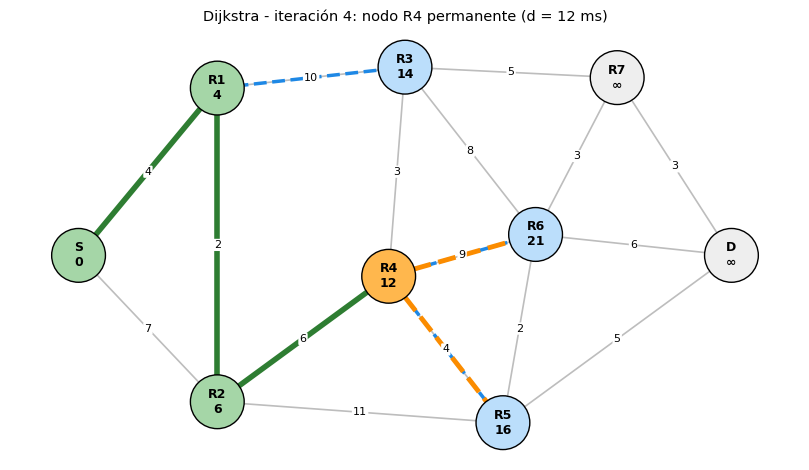

In [8]:
k_iter += 1
estado = next(pasos)
mostrar_iteracion(k_iter, estado)

## Iteración 5 de 9

**R3** (14). Por R3, R6 daría 22 (peor que 21, no mejora) y se fija $d(R7)=19$.

ITERACIÓN 5: el nodo R3 se vuelve PERMANENTE con d(R3) = 14 ms

Relajación de los vecinos temporales:
vecino d actual  d(u) + c(u,v)           ¿mejora?
    R6       21 d(R3) + 8 = 22                 no
    R7        ∞ d(R3) + 5 = 19 SÍ -> se actualiza

Estado de las etiquetas:
nodo distancia predecesor   etiqueta
   S         0          - PERMANENTE
  R1         4          S PERMANENTE
  R2         6         R1 PERMANENTE
  R3        14         R1 PERMANENTE
  R4        12         R2 PERMANENTE
  R5        16         R4   temporal
  R6        21         R4   temporal
  R7        19         R3   temporal
   D         ∞          -   temporal


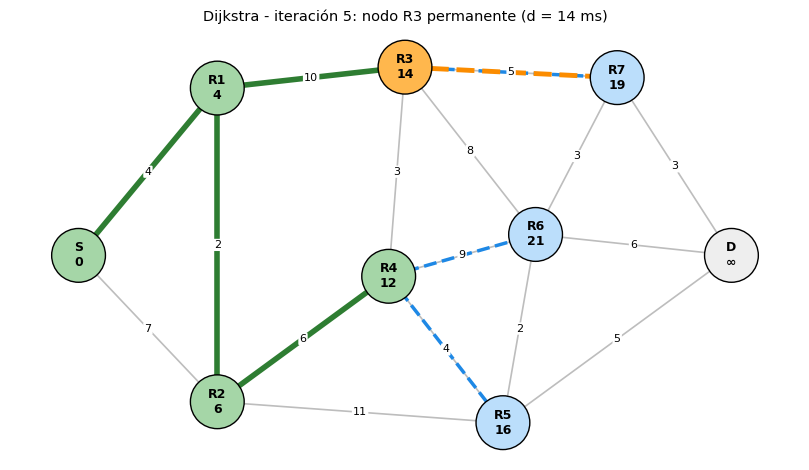

In [9]:
k_iter += 1
estado = next(pasos)
mostrar_iteracion(k_iter, estado)

## Iteración 6 de 9

**R5** (16). Aquí R6 **mejora** de 21 a 18 (16+2) y por primera vez aparece una distancia al destino: $d(D)=21$.

ITERACIÓN 6: el nodo R5 se vuelve PERMANENTE con d(R5) = 16 ms

Relajación de los vecinos temporales:
vecino d actual  d(u) + c(u,v)           ¿mejora?
    R6       21 d(R5) + 2 = 18 SÍ -> se actualiza
     D        ∞ d(R5) + 5 = 21 SÍ -> se actualiza

Estado de las etiquetas:
nodo  distancia predecesor   etiqueta
   S          0          - PERMANENTE
  R1          4          S PERMANENTE
  R2          6         R1 PERMANENTE
  R3         14         R1 PERMANENTE
  R4         12         R2 PERMANENTE
  R5         16         R4 PERMANENTE
  R6         18         R5   temporal
  R7         19         R3   temporal
   D         21         R5   temporal


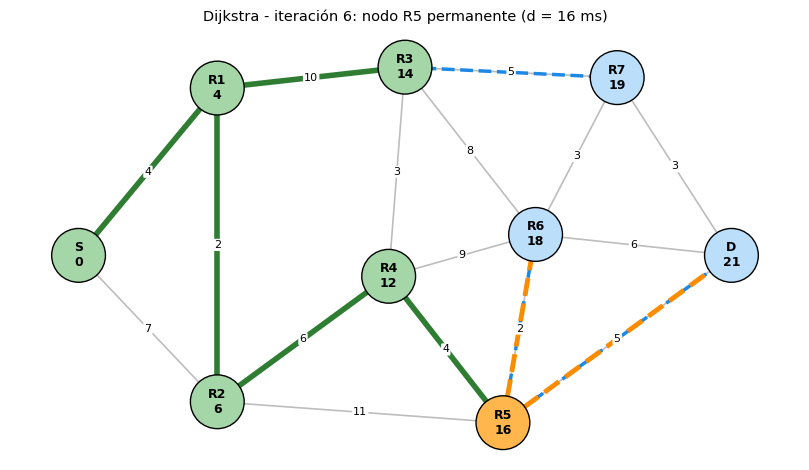

In [10]:
k_iter += 1
estado = next(pasos)
mostrar_iteracion(k_iter, estado)

## Iteración 7 de 9

**R6** (18). Por R6, R7 daría 21 (peor que 19) y D daría 24 (peor que 21): **no hay mejoras**.

ITERACIÓN 7: el nodo R6 se vuelve PERMANENTE con d(R6) = 18 ms

Relajación de los vecinos temporales:
vecino  d actual  d(u) + c(u,v) ¿mejora?
    R7        19 d(R6) + 3 = 21       no
     D        21 d(R6) + 6 = 24       no

Estado de las etiquetas:
nodo  distancia predecesor   etiqueta
   S          0          - PERMANENTE
  R1          4          S PERMANENTE
  R2          6         R1 PERMANENTE
  R3         14         R1 PERMANENTE
  R4         12         R2 PERMANENTE
  R5         16         R4 PERMANENTE
  R6         18         R5 PERMANENTE
  R7         19         R3   temporal
   D         21         R5   temporal


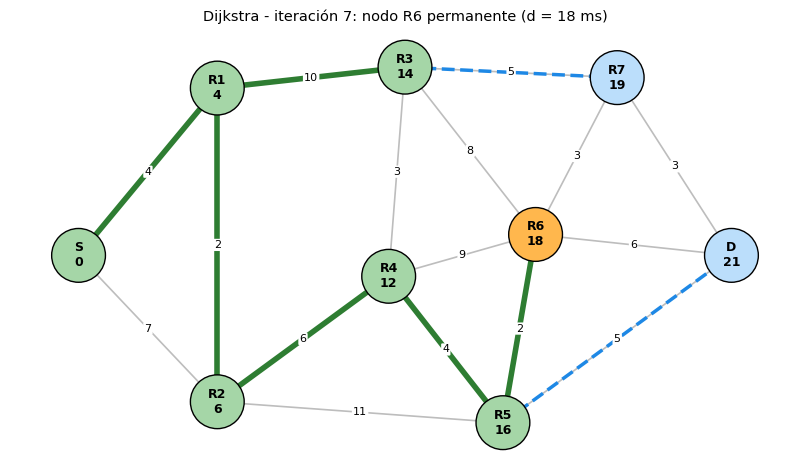

In [11]:
k_iter += 1
estado = next(pasos)
mostrar_iteracion(k_iter, estado)

## Iteración 8 de 9

**R7** (19). Por R7, D daría 22, peor que 21: no mejora.

ITERACIÓN 8: el nodo R7 se vuelve PERMANENTE con d(R7) = 19 ms

Relajación de los vecinos temporales:
vecino  d actual  d(u) + c(u,v) ¿mejora?
     D        21 d(R7) + 3 = 22       no

Estado de las etiquetas:
nodo  distancia predecesor   etiqueta
   S          0          - PERMANENTE
  R1          4          S PERMANENTE
  R2          6         R1 PERMANENTE
  R3         14         R1 PERMANENTE
  R4         12         R2 PERMANENTE
  R5         16         R4 PERMANENTE
  R6         18         R5 PERMANENTE
  R7         19         R3 PERMANENTE
   D         21         R5   temporal


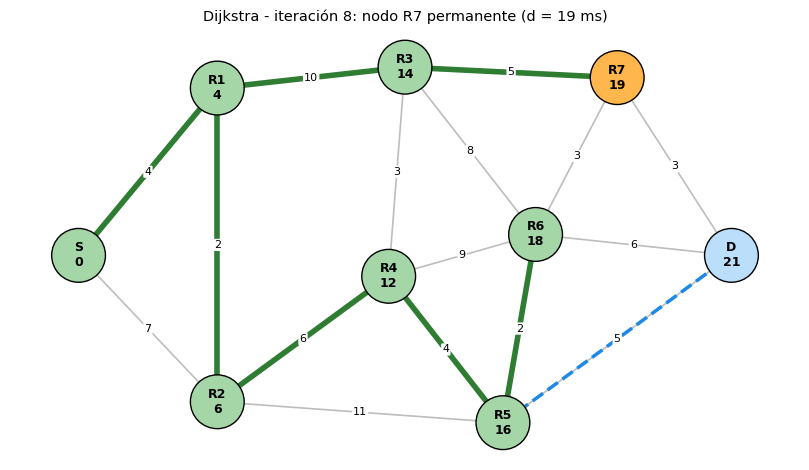

In [12]:
k_iter += 1
estado = next(pasos)
mostrar_iteracion(k_iter, estado)

## Iteración 9 de 9

**D** (21) se vuelve permanente: **el destino fue alcanzado** y su distancia ya no puede mejorar.

ITERACIÓN 9: el nodo D se vuelve PERMANENTE con d(D) = 21 ms

No hay vecinos temporales por relajar.

Estado de las etiquetas:
nodo  distancia predecesor   etiqueta
   S          0          - PERMANENTE
  R1          4          S PERMANENTE
  R2          6         R1 PERMANENTE
  R3         14         R1 PERMANENTE
  R4         12         R2 PERMANENTE
  R5         16         R4 PERMANENTE
  R6         18         R5 PERMANENTE
  R7         19         R3 PERMANENTE
   D         21         R5 PERMANENTE


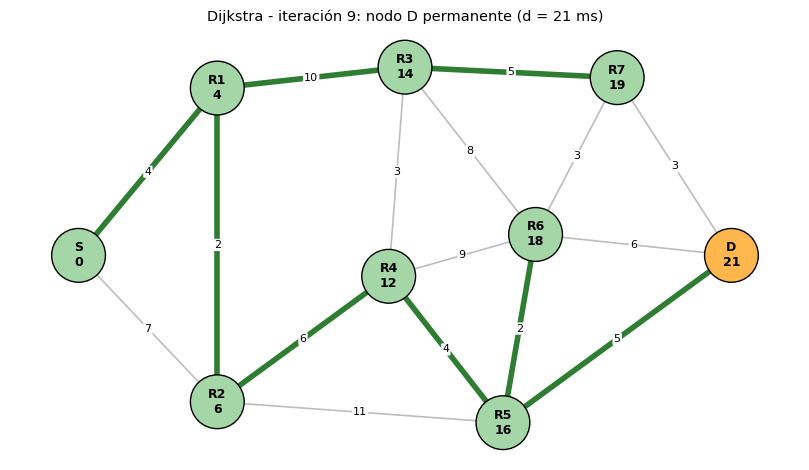

In [13]:
k_iter += 1
estado = next(pasos)
mostrar_iteracion(k_iter, estado)

# 8. Visualización de resultados

## 8.1 Reconstrucción de la ruta más corta

Se recorre la cadena de **predecesores** desde el destino D hacia el origen S y se invierte. Se muestra la latencia acumulada en cada salto y se grafica la ruta final en **rojo**.

Ruta más corta: S -> R1 -> R2 -> R4 -> R5 -> D

   salto  latencia (ms)  acumulado (ms)
 S -> R1              4               4
R1 -> R2              2               6
R2 -> R4              6              12
R4 -> R5              4              16
 R5 -> D              5              21

Distancia total S -> D = 21 ms   (suma de los saltos = 21 ms)


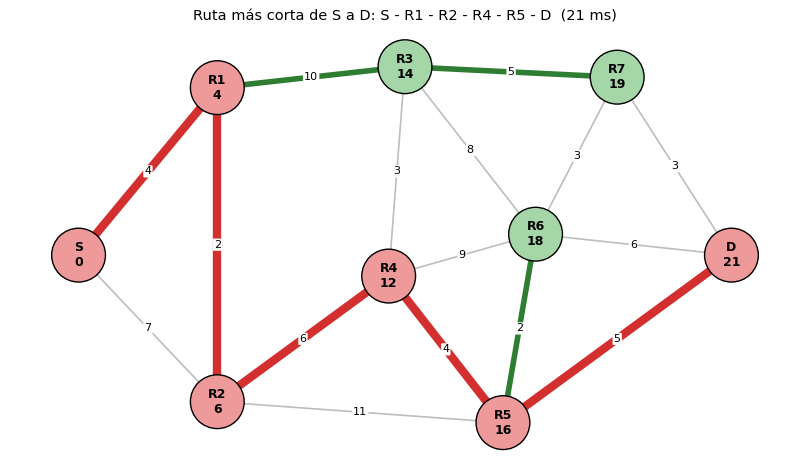

In [14]:
dist_f, pred_f = estado["dist"], estado["pred"]

camino = [destino]
while camino[-1] != origen:
    camino.append(pred_f[camino[-1]])
camino.reverse()

print("Ruta más corta:", " -> ".join(camino))
acum = 0
filas = []
for a, b in zip(camino[:-1], camino[1:]):
    w = G[a][b]["weight"]
    acum += w
    filas.append([f"{a} -> {b}", w, acum])
print()
print(pd.DataFrame(filas, columns=["salto", "latencia (ms)", "acumulado (ms)"]).to_string(index=False))
print(f"\nDistancia total S -> D = {int(dist_f[destino])} ms   (suma de los saltos = {acum} ms)")

dibujar(G, pos, dist_f, pred_f, estado["permanentes"], camino=camino,
        titulo=f"Ruta más corta de {origen} a {destino}: " + " - ".join(camino) + f"  ({acum} ms)")

## 8.2 Distancias mínimas desde S a todos los nodos

Como subproducto, Dijkstra entrega la distancia mínima desde S a **todos** los nodos (el *árbol de rutas más cortas*, que es lo que construye cada router OSPF). Se grafica el árbol completo y las distancias.

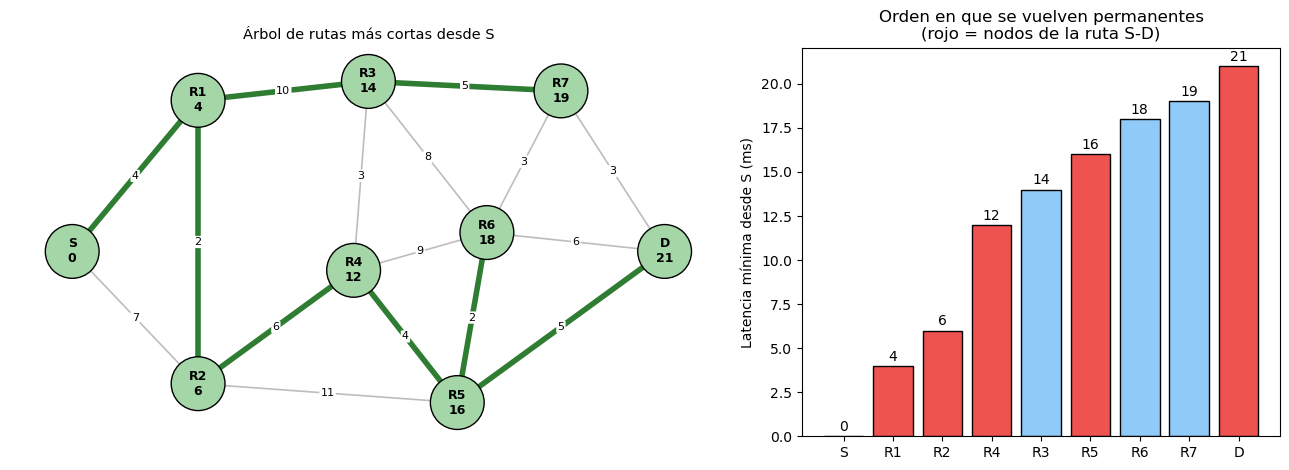

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
dibujar(G, pos, dist_f, pred_f, estado["permanentes"], titulo="Árbol de rutas más cortas desde S", ax=axs[0])
orden_perm = estado["permanentes"]
axs[1].bar(orden_perm, [dist_f[n] for n in orden_perm],
           color=["#ef5350" if n in camino else "#90caf9" for n in orden_perm], edgecolor="black")
for i, n in enumerate(orden_perm):
    axs[1].text(i, dist_f[n] + 0.3, str(int(dist_f[n])), ha="center")
axs[1].set_ylabel("Latencia mínima desde S (ms)")
axs[1].set_title("Orden en que se vuelven permanentes\n(rojo = nodos de la ruta S-D)")
plt.tight_layout()
plt.show()

## 8.3 Justificación: comparación con rutas alternativas

Para justificar que la ruta es la mejor, se listan las **6 rutas más cortas** entre S y D (sin repetir nodos) y se comparan sus latencias. La primera debe coincidir con la solución de Dijkstra y ninguna otra puede tener una latencia menor.

                          ruta  saltos  latencia (ms)
     S - R1 - R2 - R4 - R5 - D       5             21
          S - R2 - R4 - R5 - D       4             22
          S - R1 - R3 - R7 - D       4             22
          S - R1 - R2 - R5 - D       4             22
S - R1 - R2 - R4 - R3 - R7 - D       6             23
               S - R2 - R5 - D       3             23

¿La mejor ruta coincide con Dijkstra? -> True


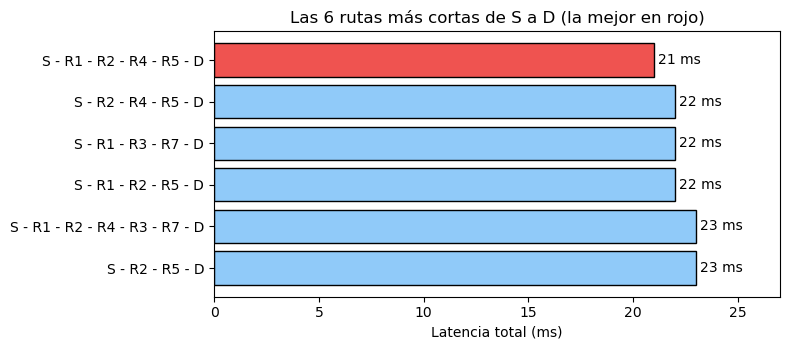

In [16]:
rutas = list(itertools.islice(nx.shortest_simple_paths(G, origen, destino, weight="weight"), 6))
filas = []
for r in rutas:
    lat = sum(G[a][b]["weight"] for a, b in zip(r[:-1], r[1:]))
    filas.append([" - ".join(r), len(r) - 1, lat])
df_rutas = pd.DataFrame(filas, columns=["ruta", "saltos", "latencia (ms)"])
print(df_rutas.to_string(index=False))
print("\n¿La mejor ruta coincide con Dijkstra? ->", rutas[0] == camino)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(df_rutas["ruta"][::-1], df_rutas["latencia (ms)"][::-1],
        color=["#ef5350" if i == 0 else "#90caf9" for i in range(len(df_rutas))][::-1], edgecolor="black")
for i, v in enumerate(df_rutas["latencia (ms)"][::-1]):
    ax.text(v + 0.2, i, f"{v} ms", va="center")
ax.set_xlabel("Latencia total (ms)")
ax.set_title("Las 6 rutas más cortas de S a D (la mejor en rojo)")
ax.set_xlim(0, max(df_rutas["latencia (ms)"]) + 4)
plt.tight_layout()
plt.show()

## 8.4 Validación con NetworkX y con programación lineal

Se verifica la solución de tres maneras independientes: (1) `dijkstra_path` de NetworkX, (2) el algoritmo de Bellman-Ford y (3) el **modelo de programación lineal** de la sección 3, resuelto con `linprog`. Los tres deben dar 21 ms.

NetworkX (Dijkstra)     : S -> R1 -> R2 -> R4 -> R5 -> D = 21 ms
NetworkX (Bellman-Ford) : S -> R1 -> R2 -> R4 -> R5 -> D

Programación lineal - estado: Optimization terminated successfully. (HiGHS Status 7: Optimal)
Valor óptimo Z = 21.0 ms
Arcos con x = 1: [('S', 'R1'), ('R1', 'R2'), ('R2', 'R4'), ('R4', 'R5'), ('R5', 'D')]

¿Los tres métodos coinciden en 21 ms? -> True
Ruta según programación lineal: S -> R1 -> R2 -> R4 -> R5 -> D


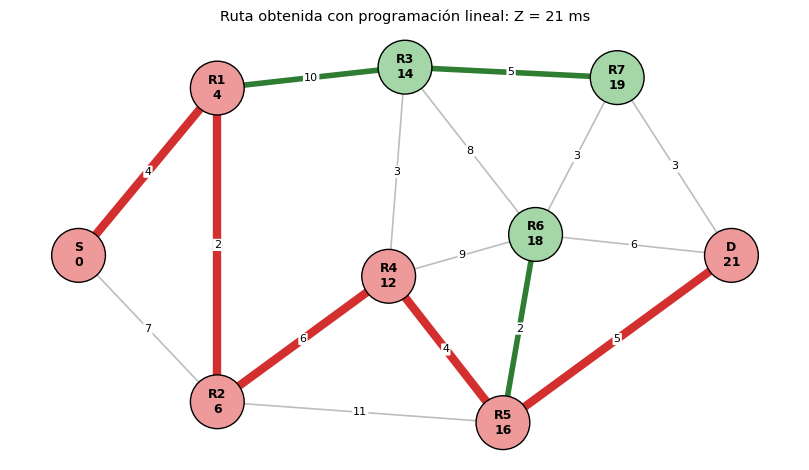

In [17]:
ruta_nx = nx.dijkstra_path(G, origen, destino, weight="weight")
lat_nx = nx.dijkstra_path_length(G, origen, destino, weight="weight")
ruta_bf = nx.bellman_ford_path(G, origen, destino, weight="weight")
print("NetworkX (Dijkstra)     :", " -> ".join(ruta_nx), f"= {lat_nx} ms")
print("NetworkX (Bellman-Ford) :", " -> ".join(ruta_bf))

# --- Modelo de programacion lineal: una variable por arco dirigido ---
arcos = []
for a, b, w in enlaces:
    arcos.append((a, b, w))
    arcos.append((b, a, w))
c = [w for _, _, w in arcos]

A_eq = np.zeros((len(nodos), len(arcos)))
b_eq = np.zeros(len(nodos))
for j, (a, b, w) in enumerate(arcos):
    A_eq[nodos.index(a), j] += 1     # sale de a
    A_eq[nodos.index(b), j] -= 1     # entra a b
b_eq[nodos.index(origen)] = 1
b_eq[nodos.index(destino)] = -1

res = linprog(c, A_eq=A_eq, b_eq=b_eq, bounds=(0, None), method="highs")
print("\nProgramación lineal - estado:", res.message)
print("Valor óptimo Z =", round(res.fun, 4), "ms")
usados = [(arcos[j][0], arcos[j][1]) for j in range(len(arcos)) if res.x[j] > 0.5]
print("Arcos con x = 1:", usados)
print("\n¿Los tres métodos coinciden en 21 ms? ->", lat_nx == round(res.fun) == int(dist_f[destino]))

siguiente = dict(usados)
ruta_lp = [origen]
while ruta_lp[-1] != destino:
    ruta_lp.append(siguiente[ruta_lp[-1]])
print("Ruta según programación lineal:", " -> ".join(ruta_lp))
dibujar(G, pos, dist_f, pred_f, estado["permanentes"], camino=ruta_lp,
        titulo=f"Ruta obtenida con programación lineal: Z = {res.fun:.0f} ms")

## 8.5 Simulación de falla de un enlace (aplicación a TI)

Los protocolos de enrutamiento **recalculan** Dijkstra cuando un enlace se cae. Se simula la falla del enlace **R5–D** (parte de la ruta óptima) y se obtiene la **nueva ruta de respaldo**.

Falla del enlace R5-D
Ruta anterior : S -> R1 -> R2 -> R4 -> R5 -> D (21 ms)
Nueva ruta    : S -> R1 -> R3 -> R7 -> D (22 ms)
Costo de la falla: +1 ms de latencia


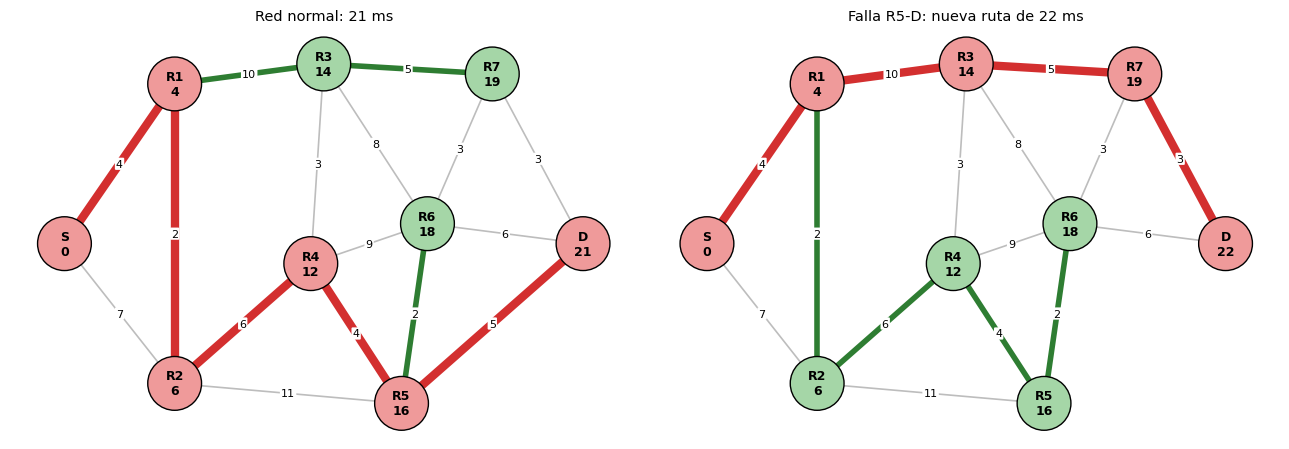

In [18]:
G_falla = G.copy()
G_falla.remove_edge("R5", "D")

dist_n, ruta_n = nx.single_source_dijkstra(G_falla, origen, destino, weight="weight")
print("Falla del enlace R5-D")
print("Ruta anterior :", " -> ".join(camino), f"({int(dist_f[destino])} ms)")
print("Nueva ruta    :", " -> ".join(ruta_n), f"({dist_n} ms)")
print(f"Costo de la falla: +{dist_n - int(dist_f[destino])} ms de latencia")

d_nuevo, p_nuevo = {}, {}
lens = nx.single_source_dijkstra_path_length(G_falla, origen, weight="weight")
for n in nodos:
    d_nuevo[n] = lens[n]
    p_nuevo[n] = None
for n in nodos:
    if n != origen:
        p_nuevo[n] = nx.dijkstra_path(G_falla, origen, n, weight="weight")[-2]

fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
dibujar(G, pos, dist_f, pred_f, nodos, camino=camino, titulo=f"Red normal: {int(dist_f[destino])} ms", ax=axs[0])
dibujar(G_falla, pos, d_nuevo, p_nuevo, nodos, camino=ruta_n, titulo=f"Falla R5-D: nueva ruta de {dist_n} ms", ax=axs[1])
plt.tight_layout()
plt.show()

# 9. Interpretación de resultados y análisis final

**Resultado principal.** La ruta de menor latencia del servidor **S** al cliente **D** es:

$$S\rightarrow R1\rightarrow R2\rightarrow R4\rightarrow R5\rightarrow D \qquad (4+2+6+4+5=\mathbf{21\ ms})$$

| Nodo | S | R1 | R2 | R4 | R3 | R5 | R6 | R7 | D |
|:-----|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|
| Orden de iteración | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
| Distancia mínima (ms) | 0 | 4 | 6 | 12 | 14 | 16 | 18 | 19 | 21 |

**Justificación e interpretación.**

- Dijkstra es **voraz**: siempre fija el nodo temporal más cercano. Como ninguna latencia es negativa, cuando un nodo se vuelve permanente ya no existe un camino más corto hacia él, por lo que la solución es **óptima**.
- El algoritmo **mejoró etiquetas** en tres momentos clave (iteraciones 2, 4 y 6): R2 bajó de 7 a 6 ms al pasar por R1; R5 bajó de 17 a 16 ms al pasar por R4; y R6 bajó de 21 a 18 ms al pasar por R5. Esto muestra que el enlace directo "más corto" **no siempre** da la ruta óptima (el camino directo S–R2 de 7 ms es peor que S–R1–R2 de 6 ms).
- Existen **tres rutas alternativas empatadas en 22 ms** (S–R2–R4–R5–D, S–R1–R2–R5–D y S–R1–R3–R7–D), sólo 1 ms más que la óptima; ninguna alternativa supera a la solución encontrada, que es la única de 21 ms.
- El resultado coincide con las funciones de NetworkX (Dijkstra y Bellman-Ford) y con la **solución del modelo de programación lineal** (Z = 21), lo que valida la implementación.

**Aplicación al área de Tecnologías de la Información.**

- Es el cálculo que hace cada router **OSPF/IS-IS** para llenar su tabla de rutas: construye el árbol de rutas más cortas desde sí mismo (sección 8.2) y reenvía los paquetes por el siguiente salto de ese árbol.
- Si la métrica fuera el **costo de ancho de banda** o el número de saltos, el mismo algoritmo aplicaría cambiando sólo los pesos; con latencia, minimiza el *tiempo de respuesta* percibido por el usuario.
- La simulación de **falla del enlace R5–D** muestra la **convergencia** del enrutamiento: el algoritmo se vuelve a ejecutar y encuentra la ruta de respaldo S–R1–R3–R7–D con **22 ms** (sólo +1 ms), lo que indica que la red tiene buena redundancia en esa zona.

# 10. Conclusiones individuales y del equipo

## Conclusión del equipo

El algoritmo de Dijkstra permitió encontrar la ruta de menor latencia entre el servidor y el cliente (**21 ms**) y, además, las distancias mínimas a todos los nodos. La ejecución iteración por iteración, con la gráfica de etiquetas permanentes y temporales, mostró cómo se actualizan las distancias y por qué el algoritmo garantiza la optimalidad. La validación con NetworkX, con Bellman-Ford y con el modelo de programación lineal confirmó el resultado y conectó este tema con los demás modelos de red de la materia y con el enrutamiento real en redes de computadoras.

## Conclusión individual

**Integrante 1 – [Nombre]:** *(escribir aquí la conclusión personal: qué aprendió, qué dificultad tuvo y cómo aplicaría el modelo)*

**Integrante 2 – [Nombre]:** *(escribir aquí la conclusión personal)*

**Integrante 3 – [Nombre]:** *(escribir aquí la conclusión personal)*